# 05 - Fine-tuning and Final Evaluation

In this notebook we take the three models shortlisted in notebook 04 (gradient boosting, random forest and logistic regression), tune them, try an ensemble, choose an approval threshold, and then evaluate the final model on the 2016 test set.

Sections 1 to 4 only use `data/train.csv`. We load `data/test.csv` once, in section 5, after the model and the threshold are fixed.

Some steps take a few minutes, so their results are saved in the `results/` folder and loaded on the next run. Delete that folder to recompute everything (about 15 minutes).

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.stats import loguniform, randint, uniform
from threadpoolctl import threadpool_limits

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, StackingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve

from preprocessing import load_split, build_preprocessor

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)
_ = threadpool_limits(limits=2)  # folds run in parallel, so limit threads per process

RANDOM_STATE = 42
os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)

X_train, y_train = load_split("../data/train.csv")
print(X_train.shape, f"default rate: {y_train.mean():.2%}")

# same folds as notebook 04
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"ROC_AUC": "roc_auc", "AP": "average_precision"}

(150000, 14) default rate: 18.46%


## 1. Shortlist with the shared pipeline

Before tuning, we re-ran the three shortlisted models with the shared pipeline in `preprocessing.py` and the same settings as notebook 04, to check that we start from the same results. These are our "before tuning" scores.

The FICO-only baseline is the same as in notebook 04: a logistic regression on `fico_n` only, with median imputation, a missing indicator and scaling.

In [2]:
def make_model(model):
    return Pipeline([("preprocess", build_preprocessor()), ("model", model)])

fico_only = ColumnTransformer([("fico", Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                                                   ("scaler", StandardScaler())]), ["fico_n"])])
baseline = Pipeline([("preprocess", fico_only),
                     ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])

# same settings as notebook 04
untuned = {
    "FICO-only baseline": baseline,
    "Gradient boosting": make_model(HistGradientBoostingClassifier(
        max_iter=200, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=50,
        l2_regularization=1.0, random_state=RANDOM_STATE)),
    "Random forest": make_model(RandomForestClassifier(
        n_estimators=200, max_depth=14, min_samples_leaf=20, max_features="sqrt",
        n_jobs=2, random_state=RANDOM_STATE)),
    "Logistic regression": make_model(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
}

path = "results/step1_untuned_cv.joblib"
if os.path.exists(path):
    untuned_cv = joblib.load(path)
else:
    untuned_cv = {name: cross_validate(m, X_train, y_train, cv=cv, scoring=scoring, n_jobs=5)
                  for name, m in untuned.items()}
    joblib.dump(untuned_cv, path)

step1 = pd.DataFrame({name: {"ROC_AUC": r["test_ROC_AUC"].mean(), "ROC_AUC_sd": r["test_ROC_AUC"].std(ddof=1),
                             "AP": r["test_AP"].mean(), "AP_sd": r["test_AP"].std(ddof=1)}
                      for name, r in untuned_cv.items()}).T
step1["ROC_AUC_nb04"] = [0.5904, 0.6627, 0.6608, 0.6610]   # from notebook 04
step1["AP_nb04"] = [0.2254, 0.3007, 0.2970, 0.2965]
step1.round(4)

,ROC_AUC,ROC_AUC_sd,AP,AP_sd,ROC_AUC_nb04,AP_nb04
FICO-only baseline,0.5904,0.0043,0.2254,0.0028,0.5904,0.2254
Gradient boosting,0.6627,0.0047,0.3007,0.0084,0.6627,0.3007
Random forest,0.6608,0.0041,0.2970,0.0064,0.6608,0.2970
Logistic regression,0.6610,0.0047,0.2965,0.0083,0.6610,0.2965


Our scores match notebook 04 exactly for all four models, which confirms we are using the same folds, pipeline and settings. The three models are within 0.002 ROC-AUC of each other, which is less than the variation between folds.

## 2. Hyperparameter tuning

We used `RandomizedSearchCV` on the same 5 folds, with ROC-AUC as the main metric and AP recorded as well. Random search lets us try wide ranges in a reasonable time. We gave gradient boosting the largest budget (40 configurations) because it has the most parameters, random forest 20 because it is the slowest to fit, and logistic regression 15 because it only has two parameters.

| Model | Ranges | Configs |
|---|---|---|
| Gradient boosting | learning_rate 0.01-0.2 (log), max_iter 100-800, max_leaf_nodes 7-63, min_samples_leaf 20-500, l2_regularization 0.001-10 (log), max_features 0.5-1.0 | 40 |
| Random forest | n_estimators 200-500, max_depth 8-24 or none, min_samples_leaf 5-200, max_features sqrt/0.3/0.5 | 20 |
| Logistic regression | C 0.001-10 (log), penalty l1/l2 | 15 |

Note: on data this size `HistGradientBoostingClassifier` uses early stopping by default (10% of each training fold is held out), so `max_iter` is really the maximum number of trees. The same default was used in notebook 04.

In [3]:
searches = {
    "Gradient boosting": (
        make_model(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
        {"model__learning_rate": loguniform(0.01, 0.2),
         "model__max_iter": randint(100, 801),
         "model__max_leaf_nodes": randint(7, 64),
         "model__min_samples_leaf": randint(20, 501),
         "model__l2_regularization": loguniform(1e-3, 10),
         "model__max_features": uniform(0.5, 0.5)},
        40),
    "Random forest": (
        make_model(RandomForestClassifier(n_jobs=2, random_state=RANDOM_STATE)),
        {"model__n_estimators": randint(200, 501),
         "model__max_depth": [8, 10, 12, 14, 16, 20, 24, None],
         "model__min_samples_leaf": randint(5, 201),
         "model__max_features": ["sqrt", 0.3, 0.5]},
        20),
    "Logistic regression": (
        make_model(LogisticRegression(solver="liblinear", max_iter=2000, random_state=RANDOM_STATE)),
        {"model__C": loguniform(1e-3, 10),
         "model__penalty": ["l1", "l2"]},
        15),
}

search_results = {}
for name, (pipe, params, n_iter) in searches.items():
    path = f"results/step2_search_{name.lower().replace(' ', '_')}.joblib"
    if os.path.exists(path):
        search_results[name] = joblib.load(path)
    else:
        search = RandomizedSearchCV(pipe, params, n_iter=n_iter, scoring=scoring, refit=False,
                                    cv=cv, n_jobs=5, random_state=RANDOM_STATE)
        search.fit(X_train, y_train)
        search_results[name] = pd.DataFrame(search.cv_results_)
        joblib.dump(search_results[name], path)

In [4]:
def short(params):
    # drop the "model__" prefix and round numbers so the settings are easier to read
    return {k.replace("model__", ""): round(v, 4) if isinstance(v, float) else v for k, v in params.items()}

best_params = {}
rows = []
for name, res in search_results.items():
    res = res.sort_values("rank_test_ROC_AUC")
    best = res.iloc[0]
    best_params[name] = best["params"]
    auc_folds = best[[f"split{k}_test_ROC_AUC" for k in range(5)]].astype(float)
    rows.append({"Model": name, "Configs": len(res),
                 "Untuned ROC_AUC": step1.loc[name, "ROC_AUC"],
                 "Tuned ROC_AUC": auc_folds.mean(), "Tuned ROC_AUC_sd": auc_folds.std(ddof=1),
                 "Untuned AP": step1.loc[name, "AP"], "Tuned AP": best["mean_test_AP"]})

    print(f"\n{name} - top 5 of {len(res)}")
    top = res.head(5)[["mean_test_ROC_AUC", "mean_test_AP", "params"]].copy()
    top["params"] = top["params"].apply(short)
    display(top.round(4))

tuning = pd.DataFrame(rows).set_index("Model")
tuning["Gain from tuning"] = tuning["Tuned ROC_AUC"] - tuning["Untuned ROC_AUC"]
tuning["Gain vs FICO"] = tuning["Tuned ROC_AUC"] - step1.loc["FICO-only baseline", "ROC_AUC"]
display(tuning.round(4))

for name in tuning.index:
    print(name, short(best_params[name]))


Gradient boosting - top 5 of 40


,mean_test_ROC_AUC,mean_test_AP,params
26,0.6636,0.3012,"{'l2_regularization': 0.0257, 'learning_rate': 0.0249, 'max_features': 0.5823, 'max_iter': 510, 'max_leaf_nodes': 15..."
38,0.6634,0.3007,"{'l2_regularization': 0.1663, 'learning_rate': 0.0489, 'max_features': 0.6209, 'max_iter': 403, 'max_leaf_nodes': 18..."
17,0.6633,0.3006,"{'l2_regularization': 0.3113, 'learning_rate': 0.0269, 'max_features': 0.5318, 'max_iter': 506, 'max_leaf_nodes': 30..."
34,0.6633,0.3003,"{'l2_regularization': 0.0192, 'learning_rate': 0.0175, 'max_features': 0.5204, 'max_iter': 759, 'max_leaf_nodes': 42..."
11,0.6631,0.3004,"{'l2_regularization': 5.7279, 'learning_rate': 0.1459, 'max_features': 0.7989, 'max_iter': 370, 'max_leaf_nodes': 14..."



Random forest - top 5 of 20


,mean_test_ROC_AUC,mean_test_AP,params
6,0.6612,0.2973,"{'max_depth': 16, 'max_features': 'sqrt', 'min_samples_leaf': 53, 'n_estimators': 258}"
1,0.6607,0.2966,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 25, 'n_estimators': 302}"
19,0.6606,0.2963,"{'max_depth': 16, 'max_features': 'sqrt', 'min_samples_leaf': 86, 'n_estimators': 252}"
0,0.6600,0.2961,"{'max_depth': 24, 'max_features': 'sqrt', 'min_samples_leaf': 19, 'n_estimators': 306}"
15,0.6600,0.2963,"{'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 138, 'n_estimators': 253}"



Logistic regression - top 5 of 15


,mean_test_ROC_AUC,mean_test_AP,params
8,0.6610,0.2966,"{'C': 2.1368, 'penalty': 'l2'}"
11,0.6610,0.2967,"{'C': 0.2796, 'penalty': 'l1'}"
2,0.6610,0.2967,"{'C': 0.2481, 'penalty': 'l1'}"
6,0.6610,0.2965,"{'C': 0.6797, 'penalty': 'l2'}"
13,0.6609,0.2965,"{'C': 0.1256, 'penalty': 'l1'}"


,Configs,Untuned ROC_AUC,Tuned ROC_AUC,Tuned ROC_AUC_sd,Untuned AP,Tuned AP,Gain from tuning,Gain vs FICO
Model,,,,,,,,
Gradient boosting,40,0.6627,0.6636,0.0046,0.3007,0.3012,0.0009,0.0733
Random forest,20,0.6608,0.6612,0.0039,0.2970,0.2973,0.0004,0.0708
Logistic regression,15,0.6610,0.6610,0.0047,0.2965,0.2966,0.0001,0.0707


Gradient boosting {'l2_regularization': 0.0257, 'learning_rate': 0.0249, 'max_features': 0.5823, 'max_iter': 510, 'max_leaf_nodes': 15, 'min_samples_leaf': 337}
Random forest {'max_depth': 16, 'max_features': 'sqrt', 'min_samples_leaf': 53, 'n_estimators': 258}
Logistic regression {'C': 2.1368, 'penalty': 'l2'}


Tuning made very little difference. The biggest gain was +0.0009 ROC-AUC for gradient boosting, about a fifth of the fold standard deviation (0.0046). The top 5 gradient boosting configurations are all between 0.663 and 0.664 even though their settings are quite different. We think performance is limited by the information in the 8 application inputs, not by the hyperparameters.

The tuned scores are also slightly optimistic, because we picked the best of many configurations on the same folds. The test set in section 5 gives the unbiased number.

## 3. Ensembles

To compare models fairly and to choose the threshold later, we need out-of-fold (OOF) predictions: every training loan gets a prediction from the fold model that did not train on it.

We tried two ensembles of the three tuned models:
- **Soft voting:** the average of the three predicted probabilities. Averaging the OOF predictions gives the same result as fitting a `VotingClassifier` in each fold.
- **Stacking:** a `StackingClassifier` with a logistic regression on top. It learns the weights using an inner 5-fold CV inside each training fold.

Before running this, we agreed to only use an ensemble if it beat the best single model by more than one fold standard deviation, since it means running three models instead of one.

In [5]:
def tuned(name):
    return clone(searches[name][0]).set_params(**best_params[name])

candidates = {
    "FICO-only baseline": baseline,
    "Gradient boosting": tuned("Gradient boosting"),
    "Random forest": tuned("Random forest"),
    "Logistic regression": tuned("Logistic regression"),
    "Stacking ensemble": StackingClassifier(
        estimators=[("gb", tuned("Gradient boosting")), ("rf", tuned("Random forest")),
                    ("lr", tuned("Logistic regression"))],
        final_estimator=LogisticRegression(max_iter=1000),
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
        stack_method="predict_proba"),
}
folds = list(cv.split(X_train, y_train))

def fit_and_predict(model, train_idx, valid_idx):
    model = clone(model).fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
    proba = model.predict_proba(X_train.iloc[valid_idx])[:, 1]
    weights = model.final_estimator_.coef_.ravel() if hasattr(model, "final_estimator_") else None
    return proba, weights

oof = {}
for name, model in candidates.items():
    path = f"results/step3_oof_{name.lower().replace(' ', '_').replace('-', '_')}.joblib"
    if os.path.exists(path):
        saved = joblib.load(path)
    else:
        out = Parallel(n_jobs=5)(delayed(fit_and_predict)(model, t, v) for t, v in folds)
        pred = np.zeros(len(y_train))
        for (_, v), (proba, _) in zip(folds, out):
            pred[v] = proba
        saved = {"oof": pred, "stack_weights": [w for _, w in out]}
        joblib.dump(saved, path)
    oof[name] = saved["oof"]
    if name == "Stacking ensemble":
        stack_weights = saved["stack_weights"]

oof["Soft-voting ensemble"] = np.mean([oof["Gradient boosting"], oof["Random forest"],
                                      oof["Logistic regression"]], axis=0)

In [6]:
rows = []
for name, p in oof.items():
    for k, (_, v) in enumerate(folds):
        rows.append({"Model": name, "Fold": k + 1,
                     "ROC_AUC": roc_auc_score(y_train.iloc[v], p[v]),
                     "AP": average_precision_score(y_train.iloc[v], p[v])})
fold_scores = pd.DataFrame(rows)

summary = fold_scores.groupby("Model")[["ROC_AUC", "AP"]].agg(["mean", "std"])
summary.columns = ["ROC_AUC", "ROC_AUC_sd", "AP", "AP_sd"]

# compare each model with tuned gradient boosting fold by fold
gb_folds = fold_scores.loc[fold_scores.Model == "Gradient boosting", "ROC_AUC"].values
for name in summary.index:
    diff = fold_scores.loc[fold_scores.Model == name, "ROC_AUC"].values - gb_folds
    summary.loc[name, "Diff vs GB"] = diff.mean()
    summary.loc[name, "Folds better than GB"] = (diff > 0).sum()
summary = summary.sort_values("ROC_AUC", ascending=False)
display(summary.round(4))

print("Stacking weights in each fold (GB, RF, LR):")
print(np.round(stack_weights, 3))
print("\nCorrelation between the OOF predictions:")
display(pd.DataFrame({n: oof[n] for n in ["Gradient boosting", "Random forest", "Logistic regression"]}).corr().round(3))

,ROC_AUC,ROC_AUC_sd,AP,AP_sd,Diff vs GB,Folds better than GB
Model,,,,,,
Stacking ensemble,0.6642,0.0044,0.3011,0.0085,0.0006,5.0
Soft-voting ensemble,0.6642,0.0044,0.3011,0.0084,0.0006,5.0
Gradient boosting,0.6636,0.0046,0.3012,0.0085,0.0000,0.0
Random forest,0.6612,0.0039,0.2973,0.0065,-0.0025,0.0
Logistic regression,0.6610,0.0047,0.2966,0.0085,-0.0026,0.0
FICO-only baseline,0.5904,0.0043,0.2254,0.0028,-0.0733,0.0


Stacking weights in each fold (GB, RF, LR):
[[2.453 1.984 2.404]
 [2.455 1.946 2.384]
 [2.446 1.97  2.383]
 [2.462 1.988 2.399]
 [2.453 1.99  2.41 ]]

Correlation between the OOF predictions:


,Gradient boosting,Random forest,Logistic regression
Gradient boosting,1.000,0.968,0.958
Random forest,0.968,1.000,0.933
Logistic regression,0.958,0.933,1.000


Both ensembles scored 0.6642, compared with 0.6636 for tuned gradient boosting. They were better in all 5 folds, but only by 0.0006, which is far below one fold standard deviation (0.0046), and AP did not improve at all. The three models' predictions are 93-97% correlated, so they mostly agree on which loans are risky and averaging them adds very little. The stacking weights are almost equal in every fold, so stacking ends up doing the same thing as a simple average.

**Following our rule, we kept tuned gradient boosting as the final model.**

## 4. Choosing the approval threshold

The business question is: if we only approve the safest X% of loans, what is the default rate among the approved loans? We sort the loans by predicted risk, lowest first, and approve the first X%.

We used the OOF predictions on the training set to draw the whole curve, and chose **80%** as our main policy before opening the test set.

The FICO baseline only has a few dozen different score values, so many loans are tied. To approve exactly 80% for both models, we break ties randomly (seed 42).

On the test set we apply the policy in two ways:
1. Approve the safest 80% of the test loans. This is our main result.
2. Use the score cutoff from the training set. This shows whether the scores shifted in 2016.

In [7]:
final = "Gradient boosting"
base = "FICO-only baseline"
colors = {final: "#2a78d6", base: "#eb6834"}

def approve_safest(scores, rate, seed=42):
    # sort by score, ties broken in random order, and approve the lowest `rate` share
    tie_break = np.random.default_rng(seed).random(len(scores))
    order = np.lexsort((tie_break, scores))
    approved = np.zeros(len(scores), dtype=bool)
    approved[order[:int(round(rate * len(scores)))]] = True
    return approved

def policy_results(y, approved):
    y = np.asarray(y)
    return {"approval_rate": approved.mean(), "approved": approved.sum(),
            "default_rate_approved": y[approved].mean(),
            "default_rate_rejected": y[~approved].mean() if (~approved).any() else np.nan}

rates = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
curve = pd.DataFrame([{"model": m, "rate": r, **policy_results(y_train, approve_safest(oof[m], r))}
                      for m in [final, base] for r in rates])

table = curve.pivot(index="rate", columns="model", values="default_rate_approved") * 100
table["GB reduction vs FICO (pp)"] = table[base] - table[final]
print(f"Training OOF - default rate (%) among the safest X% (everyone: {y_train.mean():.2%})")
table.round(2)

Training OOF - default rate (%) among the safest X% (everyone: 18.46%)


model,FICO-only baseline,Gradient boosting,GB reduction vs FICO (pp)
rate,,,
0.1,8.75,5.57,3.18
0.2,10.77,7.46,3.31
0.3,12.26,9.19,3.07
0.4,13.42,10.38,3.04
0.5,14.47,11.48,2.98
0.6,15.48,12.65,2.82
0.7,16.31,13.77,2.54
0.8,17.08,15.06,2.02
0.9,17.80,16.50,1.30


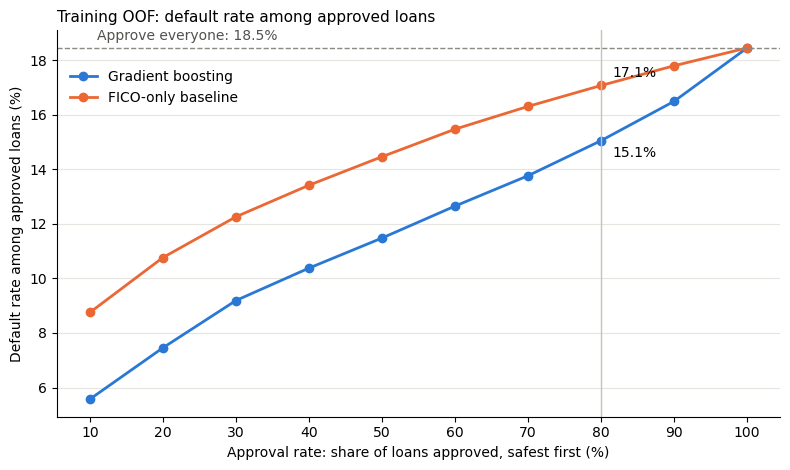

In [8]:
def plot_curve(curve, overall_rate, title, filename=None):
    fig, ax = plt.subplots(figsize=(8, 4.8))
    for m in [final, base]:
        d = curve[curve.model == m]
        ax.plot(d.rate * 100, d.default_rate_approved * 100, color=colors[m], lw=2, marker="o", ms=6, label=m)
        at80 = d[d.rate == 0.8].default_rate_approved.iloc[0]
        ax.annotate(f"{at80:.1%}", (80, at80 * 100), textcoords="offset points",
                    xytext=(8, -12 if m == final else 6))
    ax.axhline(overall_rate * 100, color="#8a8984", lw=1, ls="--")
    ax.text(11, overall_rate * 100 + 0.3, f"Approve everyone: {overall_rate:.1%}", color="#52514e")
    ax.axvline(80, color="#c3c2b7", lw=1)
    ax.set_xticks(range(10, 101, 10))
    ax.set_xlabel("Approval rate: share of loans approved, safest first (%)")
    ax.set_ylabel("Default rate among approved loans (%)")
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.93))
    plt.tight_layout()
    if filename:
        fig.savefig(filename, dpi=200)
    plt.show()

plot_curve(curve, y_train.mean(), "Training OOF: default rate among approved loans")

The model's approved loans are safer than FICO's at every approval rate. At 80%, the default rate is 15.1% with the model and 17.1% with FICO alone (18.5% if everyone is approved).

Next we fix the policy: the score cutoff that approves 80% of the training loans.

In [9]:
cutoff = {}
for m in [final, base]:
    cutoff[m] = oof[m][approve_safest(oof[m], 0.8)].max()
    print(f"{m}: approve if predicted default probability <= {cutoff[m]:.4f}")

_ = joblib.dump({"final_model": final, "approval_rate": 0.8, "tie_seed": 42, "train_cutoff": cutoff},
            "results/frozen_policy.joblib")

Gradient boosting: approve if predicted default probability <= 0.2565
FICO-only baseline: approve if predicted default probability <= 0.2281


### Errors at 80% approval (training OOF)

With default as the positive class, a rejected loan counts as a predicted default:
- false approval (FN) = approved, but the loan defaulted
- false rejection (FP) = rejected, but the loan would have been repaid

In [10]:
def confusion(y, approved):
    y = np.asarray(y)
    tp = (~approved & (y == 1)).sum()
    fn = (approved & (y == 1)).sum()
    fp = (~approved & (y == 0)).sum()
    tn = (approved & (y == 0)).sum()
    return {"Approved & repaid (TN)": tn, "Approved & defaulted (FN)": fn,
            "Rejected & repaid (FP)": fp, "Rejected & defaulted (TP)": tp,
            "Recall (defaults rejected)": tp / (tp + fn),
            "Precision (rejected that default)": tp / (tp + fp)}

pd.DataFrame({m: confusion(y_train, approve_safest(oof[m], 0.8)) for m in [final, base]}).round(4)

,Gradient boosting,FICO-only baseline
Approved & repaid (TN),101934.0000,99507.0000
Approved & defaulted (FN),18066.0000,20493.0000
Rejected & repaid (FP),20382.0000,22809.0000
Rejected & defaulted (TP),9618.0000,7191.0000
Recall (defaults rejected),0.3474,0.2598
Precision (rejected that default),0.3206,0.2397


The model rejects 35% of the defaults, compared with 26% for FICO. Still, about two thirds of the loans it rejects would have been repaid, so with only application data a lot of good borrowers get turned away.

### Calibration

We split the loans into 10 equal groups by predicted probability and compare the average prediction with the actual default rate in each group. The policy only uses the ranking, so it does not depend on calibration, but the README asks us to check it before reading the scores as probabilities.

In [11]:
prob_true, prob_pred = calibration_curve(y_train, oof[final], n_bins=10, strategy="quantile")
calib = pd.DataFrame({"predicted %": prob_pred * 100, "actual %": prob_true * 100})
calib["gap (pp)"] = calib["actual %"] - calib["predicted %"]
display(calib.round(2))

print("Brier score:")
print("  gradient boosting:", round(brier_score_loss(y_train, oof[final]), 4))
print("  FICO baseline:", round(brier_score_loss(y_train, oof[base]), 4))
print("  always predict the average:", round(brier_score_loss(y_train, np.full(len(y_train), y_train.mean())), 4))

,predicted %,actual %,gap (pp)
0,6.13,5.57,-0.56
1,9.67,9.34,-0.33
2,11.98,12.66,0.68
3,14.00,13.95,-0.05
4,16.00,15.89,-0.11
5,18.18,18.51,0.33
6,20.68,20.45,-0.23
7,23.79,24.06,0.27
8,28.03,28.04,0.01
9,36.15,36.08,-0.07


Brier score:
  gradient boosting: 0.1427
  FICO baseline: 0.1481
  always predict the average: 0.1505


On the training data the model is well calibrated: every group is within 0.7 percentage points of the actual default rate.

## 5. Final evaluation on the 2016 test set

At this point everything is fixed: the shared pipeline, tuned gradient boosting with the settings above, and the policy (safest 80%, ties broken with seed 42, training cutoff 0.2565).

We refit the final model and the FICO baseline on all 150,000 training loans and score `test.csv` once. The predictions are saved, so running the notebook again loads them instead of scoring the test set again. We did not change anything after seeing these results.

In [12]:
path = "results/step5_test_predictions.joblib"
if os.path.exists(path):
    test_run = joblib.load(path)
else:
    final_model = tuned(final).fit(X_train, y_train)
    final_baseline = clone(baseline).fit(X_train, y_train)
    X_test, y_test = load_split("../data/test.csv")
    assert pd.to_datetime(X_test["issue_d"]).dt.year.eq(2016).all()
    assert set(X_test["id"]).isdisjoint(X_train["id"])
    test_run = {"y_test": y_test.to_numpy(), "ids": X_test["id"].to_numpy(),
                "scores": {final: final_model.predict_proba(X_test)[:, 1],
                           base: final_baseline.predict_proba(X_test)[:, 1]}}
    joblib.dump(test_run, path)

y_test = test_run["y_test"]
test_scores = test_run["scores"]
print(f"Test loans: {len(y_test):,}, default rate: {y_test.mean():.2%}")

Test loans: 50,000, default rate: 23.28%


In [13]:
results = pd.DataFrame({m: {"Test ROC_AUC": roc_auc_score(y_test, test_scores[m]),
                            "Test AP": average_precision_score(y_test, test_scores[m]),
                            "Test Brier": brier_score_loss(y_test, test_scores[m]),
                            "CV ROC_AUC": summary.loc[m, "ROC_AUC"],
                            "CV AP": summary.loc[m, "AP"]}
                        for m in [base, final]}).T
print(f"AP of a random model on the test set = default rate = {y_test.mean():.4f}")
results.round(4)

AP of a random model on the test set = default rate = 0.2328


,Test ROC_AUC,Test AP,Test Brier,CV ROC_AUC,CV AP
FICO-only baseline,0.5943,0.2822,0.1774,0.5904,0.2254
Gradient boosting,0.6639,0.3598,0.1706,0.6636,0.3012


In [14]:
policies = {
    "Approve all test loans": np.ones(len(y_test), dtype=bool),
    "FICO baseline, safest 80%": approve_safest(test_scores[base], 0.8),
    "Gradient boosting, safest 80%": approve_safest(test_scores[final], 0.8),
    f"FICO baseline, training cutoff {cutoff[base]:.4f}": test_scores[base] <= cutoff[base],
    f"Gradient boosting, training cutoff {cutoff[final]:.4f}": test_scores[final] <= cutoff[final],
}
business = pd.DataFrame({name: policy_results(y_test, a) for name, a in policies.items()}).T
business[["approval_rate", "default_rate_approved", "default_rate_rejected"]] *= 100
business.round(2)

,approval_rate,approved,default_rate_approved,default_rate_rejected
Approve all test loans,100.00,50000.0,23.28,NaN
"FICO baseline, safest 80%",80.00,40000.0,21.56,30.15
"Gradient boosting, safest 80%",80.00,40000.0,19.50,38.42
"FICO baseline, training cutoff 0.2281",81.24,40621.0,21.70,30.15
"Gradient boosting, training cutoff 0.2565",80.07,40036.0,19.50,38.46


model,FICO-only baseline,Gradient boosting,GB reduction vs FICO (pp)
rate,,,
0.1,11.36,7.26,4.10
0.2,13.57,9.69,3.88
0.3,15.57,11.83,3.75
0.4,17.12,13.16,3.97
0.5,18.40,14.86,3.54
0.6,19.40,16.38,3.02
0.7,20.57,18.03,2.54
0.8,21.56,19.50,2.07
0.9,22.48,21.08,1.40


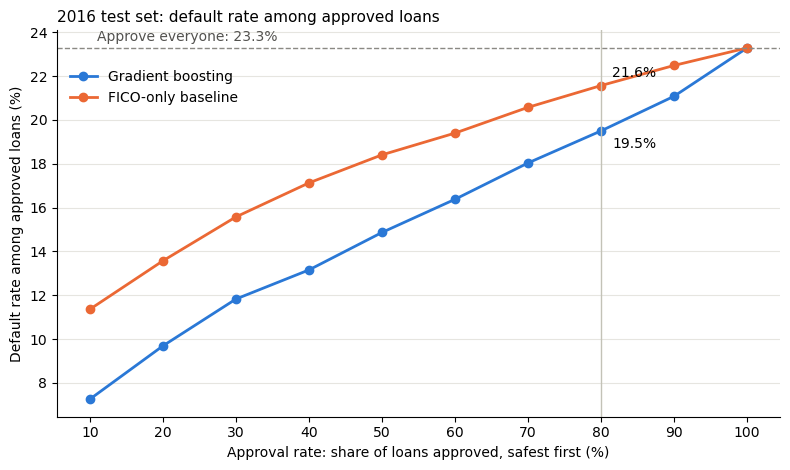

In [15]:
test_curve = pd.DataFrame([{"model": m, "rate": r, **policy_results(y_test, approve_safest(test_scores[m], r))}
                           for m in [final, base] for r in rates])
test_table = test_curve.pivot(index="rate", columns="model", values="default_rate_approved") * 100
test_table["GB reduction vs FICO (pp)"] = test_table[base] - test_table[final]
display(test_table.round(2))

plot_curve(test_curve, y_test.mean(), "2016 test set: default rate among approved loans",
           "figures/test_approval_curve.png")

Errors at 80% approval, test set


,Gradient boosting,FICO-only baseline
Approved & repaid (TN),32201.0000,31374.0000
Approved & defaulted (FN),7799.0000,8626.0000
Rejected & repaid (FP),6158.0000,6985.0000
Rejected & defaulted (TP),3842.0000,3015.0000
Recall (defaults rejected),0.3300,0.2590
Precision (rejected that default),0.3842,0.3015


Calibration on the test set


,predicted %,actual %,gap (pp)
0,6.17,7.26,1.09
1,9.70,12.12,2.42
2,12.02,16.10,4.08
3,14.01,17.14,3.13
4,15.98,21.70,5.72
5,18.15,23.94,5.79
6,20.66,27.98,7.32
7,23.74,29.74,6.00
8,28.11,33.72,5.61
9,36.34,43.12,6.78


Mean predicted default: 18.49%, actual: 23.28%


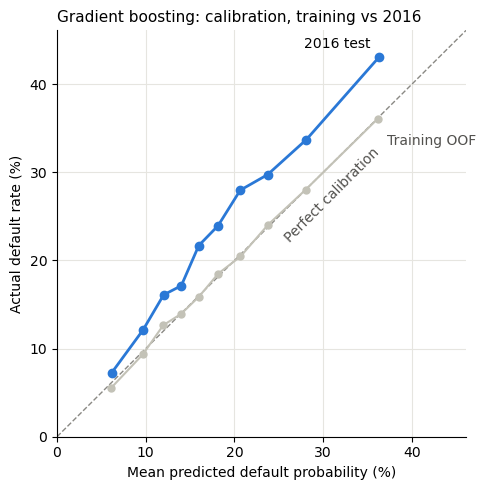

In [16]:
print("Errors at 80% approval, test set")
display(pd.DataFrame({m: confusion(y_test, approve_safest(test_scores[m], 0.8)) for m in [final, base]}).round(4))

prob_true_t, prob_pred_t = calibration_curve(y_test, test_scores[final], n_bins=10, strategy="quantile")
calib_t = pd.DataFrame({"predicted %": prob_pred_t * 100, "actual %": prob_true_t * 100})
calib_t["gap (pp)"] = calib_t["actual %"] - calib_t["predicted %"]
print("Calibration on the test set")
display(calib_t.round(2))
print(f"Mean predicted default: {test_scores[final].mean():.2%}, actual: {y_test.mean():.2%}")

fig, ax = plt.subplots(figsize=(5, 5))
lim = prob_true_t.max() * 100 + 3
ax.plot([0, lim], [0, lim], color="#8a8984", lw=1, ls="--")
ax.text(lim * 0.55, lim * 0.48, "Perfect calibration", color="#52514e", rotation=45)
ax.plot(prob_pred * 100, prob_true * 100, color="#c3c2b7", lw=1.5, marker="o", ms=5)
ax.plot(prob_pred_t * 100, prob_true_t * 100, color=colors[final], lw=2, marker="o", ms=6)
ax.text(prob_pred[-1] * 100 + 1, prob_true[-1] * 100 - 3, "Training OOF", color="#52514e")
ax.text(prob_pred_t[-1] * 100 - 1, prob_true_t[-1] * 100 + 1, "2016 test", ha="right")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_xlabel("Mean predicted default probability (%)")
ax.set_ylabel("Actual default rate (%)")
ax.set_title("Gradient boosting: calibration, training vs 2016", loc="left", fontsize=11)
ax.grid(color="#e6e5e0", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig("figures/calibration_train_vs_2016.png", dpi=200)
plt.show()

To check that the difference between the model and the baseline is not just luck, we resampled the test set 1,000 times (bootstrap) and recalculated the differences each time.

In [17]:
path = "results/step5_bootstrap.joblib"
if os.path.exists(path):
    boot = joblib.load(path)
else:
    rng = np.random.default_rng(RANDOM_STATE)
    gb, fico = test_scores[final], test_scores[base]
    rows = []
    for _ in range(1000):
        idx = rng.integers(0, len(y_test), len(y_test))
        y_b = y_test[idx]
        rows.append({
            "ROC_AUC diff": roc_auc_score(y_b, gb[idx]) - roc_auc_score(y_b, fico[idx]),
            "AP diff": average_precision_score(y_b, gb[idx]) - average_precision_score(y_b, fico[idx]),
            "Default rate @80% diff (pp)": (y_b[approve_safest(gb[idx], 0.8)].mean()
                                            - y_b[approve_safest(fico[idx], 0.8)].mean()) * 100})
    boot = pd.DataFrame(rows)
    joblib.dump(boot, path)

print("Gradient boosting minus FICO baseline (1,000 bootstrap samples)")
pd.DataFrame({"mean": boot.mean(), "2.5%": boot.quantile(0.025), "97.5%": boot.quantile(0.975)}).round(4)

Gradient boosting minus FICO baseline (1,000 bootstrap samples)


,mean,2.5%,97.5%
ROC_AUC diff,0.0698,0.0641,0.0756
AP diff,0.0779,0.0708,0.0850
Default rate @80% diff (pp),-2.1030,-2.3651,-1.8500


### Results

- **Ranking:** test ROC-AUC is 0.664 for the model and 0.594 for FICO, almost the same as in CV (0.664 and 0.590). So the model holds up on a later year, and the CV estimate was not too optimistic.
- **Business question:** approving the safest 80% of 2016 loans gives a default rate of **19.50%**, compared with **21.56%** with FICO alone and **23.28%** if every loan is approved. The difference from FICO is -2.1 points (95% interval -2.37 to -1.85), and the model is better at every approval rate from 10% to 90%.
- **Training cutoff:** using the cutoff from training approves 80.07% of the 2016 loans, very close to the planned 80%.
- **Calibration:** this is the main problem. For 2016 loans the model predicts an average default rate of 18.5%, but 23.3% actually defaulted, and most groups are 3-7 points too low. The ranking still works, so the policy is fine, but the scores should not be read as real default probabilities for a new year unless they are recalibrated on recent loans.

## 6. Model comparison chart

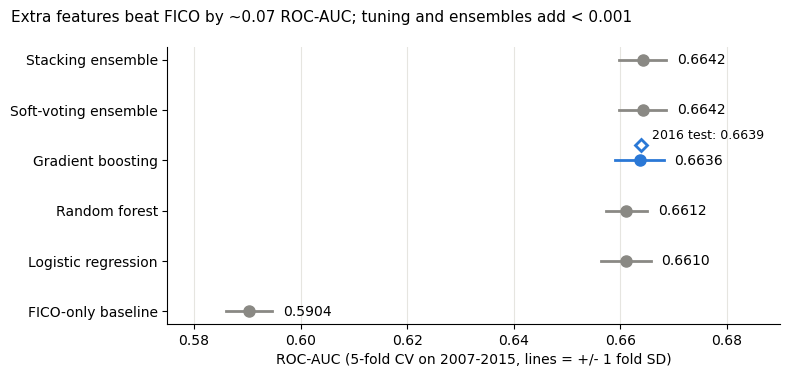

In [18]:
order = ["FICO-only baseline", "Logistic regression", "Random forest", "Gradient boosting",
         "Soft-voting ensemble", "Stacking ensemble"]
fig, ax = plt.subplots(figsize=(8, 3.8))
for i, name in enumerate(order):
    mean, sd = summary.loc[name, "ROC_AUC"], summary.loc[name, "ROC_AUC_sd"]
    c = colors[final] if name == final else "#8a8984"
    ax.plot([mean - sd, mean + sd], [i, i], color=c, lw=2)
    ax.plot(mean, i, "o", color=c, ms=8)
    ax.text(mean + sd + 0.002, i, f"{mean:.4f}", va="center")
test_auc = roc_auc_score(y_test, test_scores[final])
ax.plot(test_auc, 3.3, "D", color=colors[final], ms=6, mfc="white", mew=2)
ax.text(test_auc + 0.002, 3.42, f"2016 test: {test_auc:.4f}", fontsize=9)
ax.set_yticks(range(len(order)), order)
ax.set_xlim(0.575, 0.69)
ax.set_xlabel("ROC-AUC (5-fold CV on 2007-2015, lines = +/- 1 fold SD)")
fig.suptitle("Extra features beat FICO by ~0.07 ROC-AUC; tuning and ensembles add < 0.001",
             x=0.02, ha="left", fontsize=11)
ax.grid(axis="x", color="#e6e5e0", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig("figures/model_comparison.png", dpi=200)
plt.show()

## 7. Conclusions

If we approve the safest 80% of the 2016 loans using our model, the default rate drops from 23.28% to 19.50%. With FICO alone it only drops to 21.56%.

**What worked**
- Using more application features than FICO. All the models beat FICO by about 0.07 ROC-AUC, in CV and on the test set.
- The shared pipeline (log transforms, `loan_to_income`, state encoding), which added a small improvement for every model.
- The model generalized to 2016: the test score matched CV, and the training cutoff approved almost exactly 80% of test loans.

**What did not work**
- Tuning: 75 configurations improved ROC-AUC by less than 0.001.
- Ensembles: +0.0006 over gradient boosting, below our rule, with no gain in AP. The models are too similar to help each other.

**Limitations**
- The probabilities are too low for 2016 (18.5% predicted vs 23.3% actual), so they would need recalibration before being used as probabilities.
- At 80% approval, about 6 in 10 rejected 2016 borrowers would have repaid. Without data on profits, losses and recoveries, we cannot say whether this trade-off is worth it.
- We only see loans that were approved and finished, so the results do not apply to people who were rejected (README section 14).